# Level 4 — Descriptive statistics

Here I want to explain the numbers, not just print `describe()`. An average can hide a lot when the distribution is skewed.

In [1]:
from pathlib import Path
import pandas as pd

# Works if I open Jupyter from the repo root or from notebooks/
data_path = Path("data/sales_raw.csv")
if not data_path.exists():
    data_path = Path("../data/sales_raw.csv")

df = pd.read_csv(data_path)
df.head(3)

,line_id,order_id,order_date,customer_id,city,category,product,quantity,unit_price_pkr,discount_pct,revenue_pkr,payment_method,order_status,channel,delivery_days
0,LN-00001,ORD-2025-25001,2025-05-13,C-1023,Lahore,Office,Whiteboard,4,6000,10%,21600.0,Card,Delivered,Store,10.0
1,LN-00002,ORD-2025-25001,2025-08-19,C-1134,Islamabad,Home,Wall Clock,5,3100,15%,13175.0,Cash,Delivered,Store,8.0
2,LN-00003,ORD-2025-25002,2025-09-10,C-1052,Rawalpindi,NaN,Desk Lamp,3,2592,0%,7776.0,Bank Transfer,Delivered,Online,6.0


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The column was loaded as text because of a few invalid entries
df["qty_num"] = pd.to_numeric(df["quantity"], errors="coerce")
df[["qty_num", "unit_price_pkr", "revenue_pkr", "delivery_days"]].describe()

,qty_num,unit_price_pkr,revenue_pkr,delivery_days
count,563.000000,565.000000,550.000000,448.000000
mean,2.229130,3079.968142,5971.458545,5.877232
std,3.349043,2164.379855,12623.595722,3.095153
min,1.000000,624.000000,-17808.000000,1.000000
25%,1.000000,1100.000000,1700.000000,3.000000
50%,2.000000,2700.000000,3482.800000,6.000000
75%,3.000000,4800.000000,6985.875000,8.000000
max,75.000000,8162.000000,262500.000000,11.000000


### Mean vs median

In [3]:
sales = df["revenue_pkr"].dropna()
print("Mean revenue per line:", round(sales.mean(), 2))
print("Median revenue per line:", round(sales.median(), 2))
print("Standard deviation:", round(sales.std(), 2))
print("P90:", round(sales.quantile(.90), 2))
print("Min / max:", sales.min(), sales.max())

Mean revenue per line: 5971.46
Median revenue per line: 3482.8
Standard deviation: 12623.6
P90: 14080.32
Min / max: -17808.0 262500.0


### IQR check for unusual values
IQR is a **flag for review**, not an automatic deletion rule. Returns can create valid negative revenue.

In [4]:
q1, q3 = sales.quantile([.25, .75])
iqr = q3 - q1
low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
flagged = df[(df["revenue_pkr"] < low) | (df["revenue_pkr"] > high)]
print("IQR bounds:", round(low, 2), round(high, 2))
print("Flagged rows:", len(flagged))
flagged[["line_id", "product", "quantity", "order_status", "revenue_pkr"]].head()

IQR bounds: -6228.81 14914.69
Flagged rows: 45


,line_id,product,quantity,order_status,revenue_pkr
0,LN-00001,Whiteboard,4,Delivered,21600.0
5,LN-00006,Laptop Stand,3,Delivered,15264.0
17,LN-00018,Headphones,5,Delivered,26235.0
20,LN-00021,Webcam,4,Pending,23846.4
33,LN-00034,USB-C Hub,4,Returned,-17808.0


### Look at the distribution

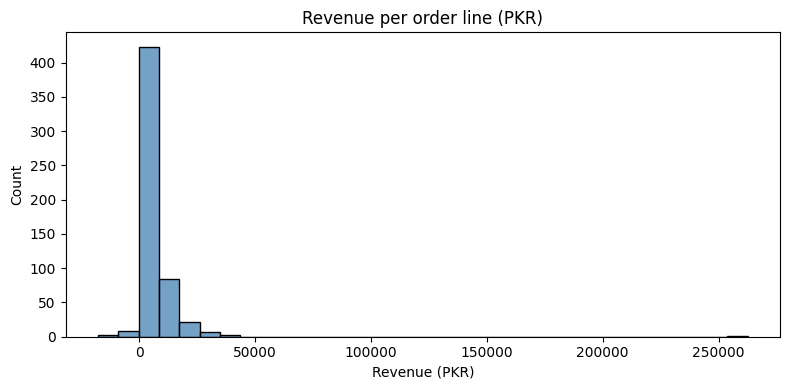

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(x=sales, bins=32, color="steelblue")
plt.title("Revenue per order line (PKR)")
plt.xlabel("Revenue (PKR)")
plt.tight_layout()
plt.show()

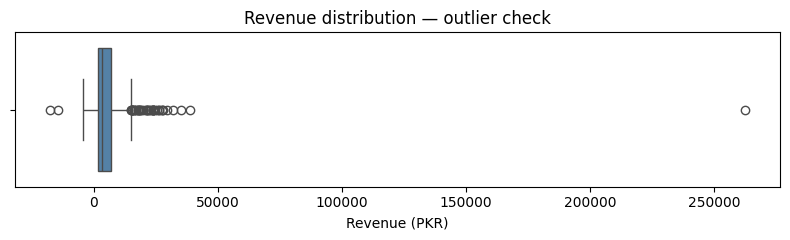

In [6]:
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=sales, color="steelblue")
plt.title("Revenue distribution — outlier check")
plt.xlabel("Revenue (PKR)")
plt.tight_layout()
plt.show()

### Grouping is useful, but raw labels can mislead

In [7]:
# Still shows Lahore and lahore separately (Level 7 will standardize them)
df.groupby("city", dropna=False)["revenue_pkr"].sum().sort_values(ascending=False).head(10)

city
Lahore        1037202.95
Karachi        501004.85
Islamabad      481734.35
Rawalpindi     369895.30
Faisalabad     334731.15
lahore         106859.50
Lhr             95138.00
 Lahore         91068.90
KHI             72466.00
LAHORE          71427.70
Name: revenue_pkr, dtype: float64

**My note:** The mean is affected by the large order line. I would report median and percentiles alongside it, and investigate the high values before excluding anything.